In [2]:
from getpass import getuser # Libaray to copy things
from pathlib import Path # Object oriented libary to deal with paths
from dask.utils import format_bytes
from distributed import Client, progress, wait # Libaray to orchestrate distributed resources
#from dask_jobqueue import SLURMCluster # Setting up distributed memories via slurm
import numpy as np # Pythons standard array library
import xarray as xr # Libary to work with labeled n-dimensional data
import dask # Distributed data libary
import dask.distributed
import multiprocessing
from dask.diagnostics import ProgressBar
import glob, os
from matplotlib.patches import Patch
from scipy.ndimage import gaussian_filter1d
from scipy import stats
from subprocess import run, PIPE
import sys
import gc
from concurrent.futures import ProcessPoolExecutor
import seaborn as sns
import warnings
warnings.filterwarnings(action='ignore')
dask.config.config.get('distributed').get('dashboard').update({'link':'{JUPYTERHUB_SERVICE_PREFIX}/proxy/{port}/status'})
import pandas as pd
from scipy.interpolate import CloughTocher2DInterpolator, LinearNDInterpolator, NearestNDInterpolator

In [3]:
from matplotlib.ticker import (MultipleLocator, FormatStrFormatter, AutoMinorLocator)
from matplotlib import pyplot as plt # Standard Plotting library
from matplotlib import cm
from matplotlib.colors import ListedColormap, LinearSegmentedColormap
from matplotlib.ticker import (MultipleLocator, FormatStrFormatter, AutoMinorLocator)
from cartopy import crs as ccrs # Cartography library
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter
import cartopy.feature as cfeature
import matplotlib.ticker as mticker
import matplotlib.tri as tri

In [4]:
#'''Provides information about the CPU and starts the dask client'''
ncpu = multiprocessing.cpu_count()
processes = False
nworker = 1
threads = ncpu // nworker
print(f"Number of CPUs: {ncpu}, number of threads: {threads}, number of workers: {nworker}, processes: {processes}")
client = Client(processes=processes,
 threads_per_worker=threads,
 n_workers=nworker,
 memory_limit='1000GB'
 )

Number of CPUs: 64, number of threads: 64, number of workers: 1, processes: False


In [5]:
ifs = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/dry_spells/IFS_cycle4_summer_1990-2049_dry_spell_annual_30-60N.nc')['__xarray_dataarray_variable__']
ifs = ifs[31:60,:]


In [6]:
#Define the yearly mean temperature change
data_path = Path('/home/jwille/xenon_data/NextGEMS/NextGEMS/IFS_zoom9/2020-2050/yearly_tmean_30-60N')
files = sorted([str(f) for f in data_path.glob(f'30-60N_IFS_9-FESOM_5_daily_year_tmean_*.nc')])[:]
ifs_tmean = xr.open_mfdataset(files, engine='netcdf4',combine='by_coords')['2t']
ifs_tmean = ifs_tmean[1:30,:]
land_sea_ifs_zoom9 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/NextGEMS/IFS_zoom9/30-60N_ifs_hpx512_lsm.nc')['lsm']
ifs_tmean_land = ifs_tmean.where(land_sea_ifs_zoom9 > 0, np.nan)
ifs_tmean_land_mean = ifs_tmean_land.mean(dim='value').load()
ifs_tmean_land_diff = ifs_tmean_land_mean - ifs_tmean_land_mean[0]

In [17]:
from scipy.interpolate import BSpline

TREND_METHOD  = 'spline'   # 'linear' (straight line, as before) or 'spline'
KNOT_SPACING  = 10         # years between spline knots: larger = smoother (29 years / 10 -> 2 interior knots)
SPLINE_DEGREE = 3          # cubic


def spline_basis(t, knot_spacing=KNOT_SPACING, k=SPLINE_DEGREE):
    """B-spline basis (n_years x n_basis) with interior knots about every knot_spacing years."""
    n_int = max(int(round((t[-1] - t[0]) / knot_spacing)) - 1, 0)
    interior = np.linspace(t[0], t[-1], n_int + 2)[1:-1]
    knots = np.r_[[t[0]] * (k + 1), interior, [t[-1]] * (k + 1)]
    n_basis = len(knots) - k - 1
    return np.column_stack([BSpline(knots, np.eye(n_basis)[i], k)(t) for i in range(n_basis)])


def trend_basis(t):
    """Columns of the trend model: [1, t] for a straight line, the B-spline basis for a spline."""
    t = np.asarray(t, dtype=float)
    return np.column_stack([np.ones_like(t), t]) if TREND_METHOD == 'linear' else spline_basis(t)


def smooth_trend(t, y):
    """Least-squares fit of the trend model to y, evaluated at t."""
    B = trend_basis(t)
    return B @ np.linalg.lstsq(B, y, rcond=None)[0]

In [18]:
ifs_land = ifs.where(land_sea_ifs_zoom9 > 0, np.nan)
ifs_land_mean = ifs_land.mean(dim='value')
yrs = np.arange(ifs_tmean_land_mean.size)
x_trend = smooth_trend(yrs, ifs_tmean_land_mean.values)      # straight line or spline (TREND_METHOD)
ifs_lin = stats.linregress(x_trend, ifs_land_mean.values)
print(TREND_METHOD, ifs_lin)

spline LinregressResult(slope=2.448948417840356, intercept=23.39656273656551, rvalue=0.6891608977182969, pvalue=3.559686447982615e-05, stderr=0.49554198969164914, intercept_stderr=4.436861575095713)


In [7]:
ifs_land = ifs.where(land_sea_ifs_zoom9 > 0, np.nan)
ifs_land_mean = ifs_land.mean(dim='value')
yrs = np.arange(ifs_tmean_land_mean.size)
x_trend = np.polyval(np.polyfit(yrs, ifs_tmean_land_mean.values, 1), yrs)
ifs_lin = stats.linregress(x_trend, ifs_land_mean.values)
print(ifs_lin)

LinregressResult(slope=2.6494803728524734, intercept=21.605728889993497, rvalue=0.7310837400080648, pvalue=6.655125215519499e-06, stderr=0.47586007587115225, intercept_stderr=4.260214708368762)


In [ ]:
plt.scatter(x_trend,icon_land_mean)

In [10]:

ifs_land = ifs.where(land_sea_ifs_zoom9 > 0, np.nan)
ifs_land_mean = ifs_land.mean(dim='value')
ifs_lin = stats.linregress(ifs_tmean_land_mean,ifs_land_mean)
print(ifs_lin)

LinregressResult(slope=2.483234697486816, intercept=23.090371984771345, rvalue=0.7304360463341257, pvalue=6.845534802283094e-06, stderr=0.44685062950096677, intercept_stderr=4.001856533852915)


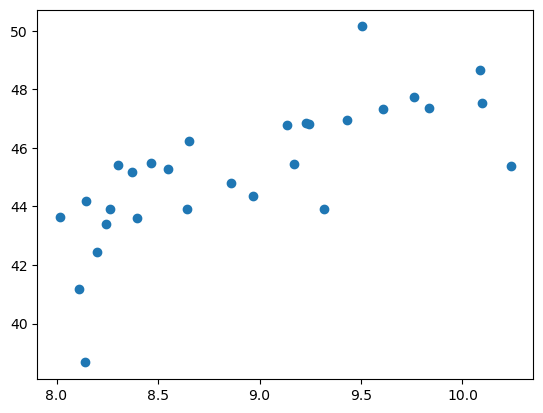

In [12]:
plt.scatter(ifs_tmean_land_mean,ifs_land_mean)

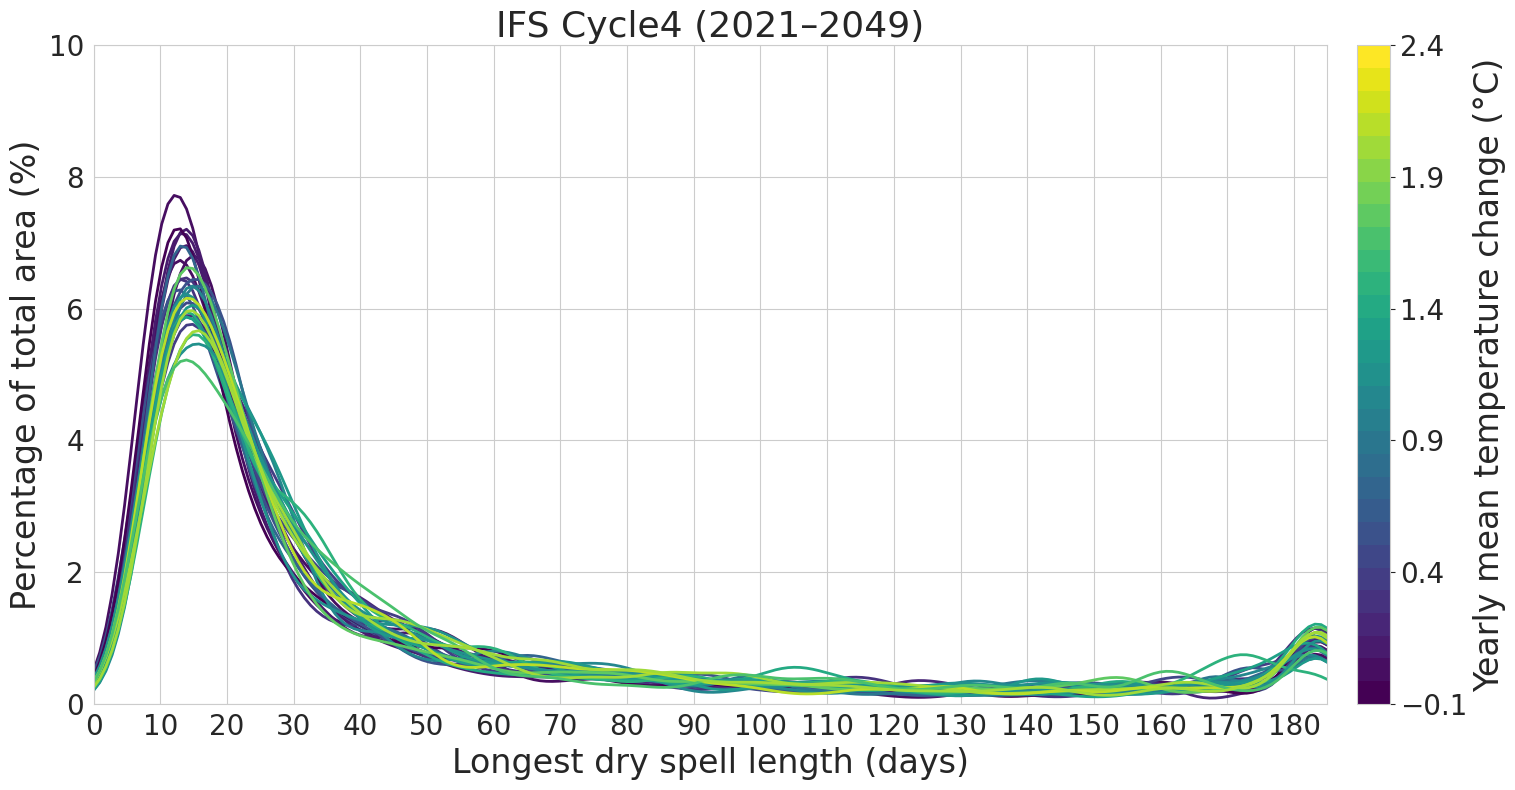

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1) Common x‐range + bin width
xmin, xmax = 0, 185
bin_width  = 2

# 2) Year indices (0–29) and number of years
years = ifs_land.year.values
n_years = len(years)

# 3) Viridis colormap
temps = ifs_tmean_land_diff.values
cmap = plt.get_cmap('viridis', n_years)
norm = plt.Normalize(
    vmin=-0.1,
    vmax=2.4
)

fig, ax = plt.subplots(figsize=(16, 8))
sns.set_style("whitegrid")

# Prepare to record the total weight for each year
sum_weights = []

# 4) Plot each year's KDE
for i, (yr, temp) in enumerate(zip(years, temps)):
    vals = ifs_land.sel(year=yr).values.ravel()
    vals = vals[~np.isnan(vals)]
    # weights that sum to 100
    w = np.ones_like(vals) * (100.0 / vals.size)
    sum_weights.append(w.sum())  # this will be 100.0 for each year

    sns.kdeplot(
        x=vals,
        weights=w,
        bw_adjust=1.0,
        clip=(xmin, xmax),
        common_norm=False,
        fill=False,
        linewidth=2.0,
        color=cmap(norm(temp)),
        legend=False
    )

# 5) Rescale from “percent per unit‐x” → “percent per 0.5%‐bin”
for line, total_w in zip(ax.get_lines(), sum_weights):
    x_vals, y_vals = line.get_data()
    y_scaled = y_vals * bin_width * total_w
    line.set_data(x_vals, y_scaled)

sm = plt.cm.ScalarMappable(
    cmap=cmap,
    norm=norm
)
sm.set_array([])

ticks = np.linspace(-0.1, 2.4, 6)

cbar = fig.colorbar(sm, ax=ax, pad=0.02, ticks=ticks)
cbar.set_label('Yearly mean temperature change (°C)', fontsize=24)
cbar.ax.tick_params(labelsize=20)
xticks = np.arange(xmin, xmax, 10)
ax.set_xticks(xticks)

# 7) polish & save

xl = 'Longest dry spell length (days)'
ax.set_ylim(0, 10)


ax.set_xlabel(xl, fontsize=24)
plt.ylabel('Percentage of total area (%)', fontsize=24)
ax.set_xlim(xmin, xmax)
ax.tick_params(axis='both', which='major', labelsize=20)
plt.title('IFS Cycle4 (2021–2049)', fontsize=26)
plt.tight_layout()
plt.savefig('/home/jwille/images/global_paper/mid_lat_land_IFS_cycle4_histo_dry_spell_temp.pdf', format='pdf',bbox_inches='tight')

plt.show()
